## <이동(translation) 변환>>

### 기본 라이브러리 불러오기

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

### User parameter 정의하기

In [8]:
# tx = x + tx
# ty = y + ty

tx = -50
ty = -30

# 일반적인 행렬
T = np.array([[tx],[ty]])
print(T)

# 동차좌표
T_h = np.array([[1,0,tx],[0,1,ty],[0,0,1]])
print(T_h)

[[-50]
 [-30]]
[[  1   0 -50]
 [  0   1 -30]
 [  0   0   1]]


### ‘cat.jpg’를 흑백영상(f)으로 읽고, 영상의 크기(h,w)를 자동으로 구하기

In [9]:
f = cv2.imread("images/cat.jpg",0) # gray
h,w = f.shape

print(h,w)

400 600


### 결과 영상(g) 생성하기

In [10]:
g = np.zeros((h,w))
gh, gw = g.shape

### 이동 구현하기

In [12]:
g = np.zeros((h,w))
gh, gw = g.shape

# forward mapping / 전방향 사상 + 선형대수
for x in range(0,h):
    for y in range(0,w):
        P = np.array([[x],[y],[1]])
        P_prime = (T_h @ P).astype("int16")   ## @ : 행렬 곱
        x_prime = int(x + tx)
        y_prime = int(y + ty)
        if (0 <= P_prime[0,0] < gh) and (0 <= P_prime[1,0] < gw): # (0 <= x_prime) and (x_prime < gh)
            g[P_prime[0,0],P_prime[1,0]] = f[x,y]     # mapping 사상

# 8bit unsigned integer format

g = g.astype("uint8")            

### matplot 라이브러리를 활용하여 영상(f,g) 출력하기

(np.float64(-0.5), np.float64(599.5), np.float64(399.5), np.float64(-0.5))

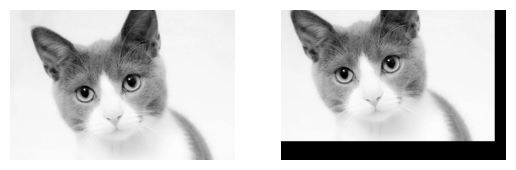

In [13]:
plt.subplot(1,2,1); plt.imshow(f, cmap="gray"); plt.axis("off")
plt.subplot(1,2,2); plt.imshow(g, cmap="gray"); plt.axis("off")